# Transport of a Pollutant in a River

## Introduction

A quantity of a pollutant has entered a river. At time $t=0$, its concentration profile is block-shaped, with a length of 10 km and a maximum concentration of 10 mg/$m^{3}$. For the river section, we have the following data: the average flow velocity is $u = 0.5$ m/s, and the diffusion coefficient is $K = 100$ $m^{2}/s$.

The objective of this assignment is to determine when the maximum concentration passes a point located 60 km downstream from the point where the pollutant was present at $t=0$. We shall refer to these two locations as B and A, respectively. Furthermore, we aim to determine the value of the maximum concentration at point B.

You are provided with the Python script containing the code for the solution of the following 1D advection-diffusion equation:

$$
  \frac{\partial c}{\partial t} + u \frac{\partial c}{\partial x} - K\frac{\partial^2 c}{\partial x^2} = 0\, , \quad x \in [0,L]
$$

where $c(x,t)$ is the concentration (in mg/$m^{3}$) and $L$ is the length of the river section (in meters). This equation describes the transport of the cloud of pollutant along the river at a constant speed while spreading in the river as time proceeds.

For the simulations and the analysis that we will carry out, the following step sizes will be used as baseline: $\Delta x = 0.4$ km and $\Delta t = 10$ minutes.

## Part I: find the solution

>**Task 1.1**
>
>Before we proceed with simulating the transport of the cloud of pollutant, we will first answer a few questions to get an idea of the problem.
>
>1. How long does it take for the peak of the cloud to pass point B?
>2. What will the profile of the cloud look like at point B and what is its maximum length? You may provide a schematic drawing.
>3. What will the maximum concentration in B be?
>
>To answer the questions above, you may use the exact solution for the **diffusion** equation ($u=0$) with a block-shaped initial cloud that is centered around $x=0$. This solution is given as:
>
>$$
>  c(x,t) = \frac{c_0}{2} \left [ \text{erf} \left ( \frac{0.5L_c-x}{2\sqrt{Kt}} \right ) + \text{erf} \left ( \frac{0.5L_c+x}{2\sqrt{Kt}} \right ) \right ]
>$$
>
>with $c_0$ the initial concentration and $L_c$ the initial cloud length.
>
> **Hint:** Use the exact solution for diffusion considering that the advection term does not change the level of the maximum concentration for given $t$. Think about at which $x$ the diffusion solution will have its maximum. You can evaluate the error function $\text{erf}(z)$ with `scipy.special.erf`.


**Answer Task 1.1**

Data: $c_0 = 10$ mg/m$^3$, $L_c = 10$ km, $u = 0.5$ m/s, $K = 100$ m$^2$/s, distance A→B $= 60$ km.

**Approach (following the hint).** Advection moves the cloud at constant speed $u$ without changing its shape. In particular, it does not change the level of the maximum concentration for a given $t$. To see this, introduce the moving coordinate $\xi = x - ut$. Then

$$
\frac{\partial c}{\partial t} + u\frac{\partial c}{\partial x} = \left.\frac{\partial c}{\partial t}\right|_{\xi},
$$

so the advection-diffusion equation becomes the pure diffusion equation $\partial c/\partial t = K\,\partial^2 c/\partial \xi^2$. The solution is therefore the diffusion solution shifted by $ut$:

$$
c(x,t) = c_{\text{diff}}(x - ut,\, t)
$$

Advection determines **where** the cloud is (and thus *when* the peak reaches B). Diffusion alone determines **how high and how wide** the cloud is at that time.

**1. Time for the peak to pass B**

The peak travels with the flow velocity:

$$
t_B = \frac{60\,000}{0.5} = 120\,000 \text{ s} \approx 33.3 \text{ h} \quad (= 200 \text{ time steps of } 10 \text{ min})
$$

**2. Shape and length of the cloud at B**

The cloud is block-shaped only at $t = 0$. For any $t > 0$, the exact solution (a sum of two error functions) is smooth: diffusion immediately rounds off the sharp edges of the block. The profile stays symmetric around the moving centre.

How far the shape has changed depends on the spreading length $2\sqrt{Kt}$ compared with the cloud length $L_c$:
- If $2\sqrt{Kt} \ll L_c$, the profile is still a block with slightly rounded edges.
- If $2\sqrt{Kt} \gg L_c$, the profile tends to a Gaussian bell curve.

At B, $2\sqrt{Kt_B} = 2\sqrt{100 \cdot 120\,000} \approx 6.9$ km, which is of the same order as $L_c = 10$ km. The cloud is therefore **neither a block nor a pure Gaussian**. It is a **smoothed block**: a lowered, rounded top with erf-shaped flanks and long tails on both sides.

As a check, a Gaussian with the same mass would have a peak of $c_0 L_c/\sqrt{4\pi K t_B} \approx 8.1$ mg/m$^3$, while the exact peak is $6.9$ mg/m$^3$ (see question 3). So the profile is clearly not yet Gaussian.

Evaluating the exact solution at $t_B$ gives the length of the cloud:
- $c$ drops below 1% of $c_0$ (0.1 mg/m$^3$) at $|\xi| \approx 16.4$ km from the centre, so the visible length is **$\approx 33$ km**.
- $c$ drops below 0.1% of $c_0$ at $|\xi| \approx 20.1$ km, so the total length is **$\approx 40$ km**.

The maximum length of the cloud at B is therefore about 35–40 km, compared with 10 km at $t = 0$.

Schematic: a symmetric, smoothed-block profile centred at B, with a peak of $\approx 6.9$ mg/m$^3$ and tails extending about $\pm 20$ km around B.

**3. Maximum concentration at B**

Because advection does not change the maximum concentration at a given $t$, the maximum at B equals the maximum of the pure diffusion solution at $t = t_B$. That maximum lies at the centre of the cloud, $\xi = 0$ (i.e. exactly at B when $t = t_B$):

$$
c_{\max}(t) = \frac{c_0}{2}\left[2\,\text{erf}\left(\frac{0.5L_c}{2\sqrt{Kt}}\right)\right] = c_0\,\text{erf}\left(\frac{L_c}{4\sqrt{Kt}}\right)
$$

At $t = t_B$:

$$
c_{\max} = 10\cdot\text{erf}\left(\frac{10\,000}{4\sqrt{100\cdot 120\,000}}\right) = 10\cdot\text{erf}(0.722) \approx \mathbf{6.9 \text{ mg/m}^3}
$$


### Python module for numerical solution to advection-diffusion equation

Here we outline the usage of the Python module `advdiff.py` in this folder, which contains the solver for the above presented advection-diffusion equation.

An initial condition $c(x,0) = c0(x)$ must be provided by the user such that $c0(0) = c0(L) = 0$, so that no boundary conditions need to be imposed.

**An important note here: choose $L$ such that the entire profile of the cloud transported along the river is completely visible in the plot.**

The use of function `advdiff` is as follows:

```
c = advdiff ( u, K, c0, L, dt, T, dxmethod, dtmethod, theta )
```

and the input parameters are defined as follows:
- `u` = flow velocity (in m/s)
- `K` = diffusion coefficient (in m$^{2}$/s)
- `c0` = initial condition (row vector)
- `L` = length of computational domain (in m)
- `dt` = time step (in s)
- `T` = simulation end time (in s)
- `dxmethod` = spatial discretization scheme
- `dtmethod` = time integration scheme
- `theta` = implicitness parameter ($0 \leq $ `theta` $\leq 1$)

The output parameter is `c` which contains the numerical solution of the advection-diffusion equation.
This variable is a 2D array `c[0:N,0:M]` with `N` the number of time steps and `M` the number of grid cells.
The grid is equidistant so that the grid points are uniformly distributed with a constant grid size $\Delta x = L/$`M`.

The row vector `c0` represents the initial value of $c(x,0)$ at uniformly spaced points in $[0,L]$.
Hence, the dimension of this vector is `c0[0:M]`.
Note that `c0` is a grid function and thus indirectly defines the computational grid. (The script therefore calculates the value of $\Delta x$ itself.)

The allowed values of `dxmethod` in this assignment are:
- `central` = second order central differences
- `upwind` = first order upwind scheme

These two methods only concern the advection term while the diffusion term is approximated exclusively with central differences.

The relevant value of `dtmethod` in this assignment is `'theta'` and represents the $\theta$-method, to be discussed in the following part.

The last argument of `advdiff` specifies the actual value of the implicitness parameter $\theta$. Special cases are
- `theta = 0.0` is forward Euler
- `theta = 0.5` is Crank-Nicolson
- `theta = 1.0` is backward Euler

**The code in the `.py` file is complete and does not need to be modified.**

Import `advdiff` in the cell below.

In [1]:
from advdiff import advdiff

>**Task 1.2**
>
>In the next cell, we specify the initial condition `c0` of the cloud of pollutant which has a *block-shaped* profile with a length of 10 km.
>Note that the maximum concentration value is 10 $mg/m^{3}$.
>For the computational domain, we must choose a length that visualizes the propagation of the bell-curve, including its head and tail, through the domain all the way. Make an estimate of this length.
>
>Fill in the missing domain length and run the cell below to plot the initial condition.
>


Text(0, 0.5, 'concentration [mg/m3]')

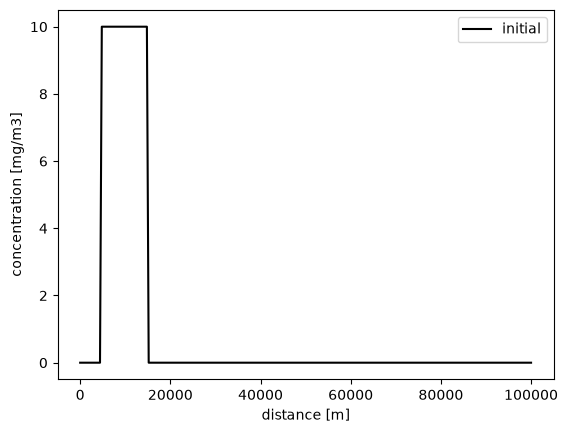

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# domain length
# initial cloud: x = 5 - 15 km (centre ~10 km)
# at t_B = 120 000 s the centre is at ~10 + 60 = 70 km, and diffusion spreads
# the cloud to about +/- 20 km around it (see Task 1.1) -> cloud spans ~50 - 90 km.
# 100 km keeps head and tail inside the domain with margin, so c = 0 at both ends,
# and it is a multiple of dx (250 cells) so the grid size is exactly 400 m.
lenD = 100000.

lenC = 10000.             # length of c0
dx = 400.                 # grid size

M = int(lenD/dx) + 1      # number of grid points
x = np.linspace(0,lenD,M) # array with coordinates of grid points

# initial condition
c0 = np.zeros(M)
c0[int(0.5 * lenC/dx):int(0.5 * lenC/dx) + int(lenC/dx) + 1] = 10.
plt.plot(x,c0,'k',label='initial')
plt.legend(loc='upper right')
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')

>**Task 1.3**
>
>We will now run the simulation using the script above. Enter the required data in the fields below and run the cell.


In [3]:
# parameters for advdiff

u = 0.5            # flow velocity [m/s]
K = 100.           # diffusion coefficient [m2/s]
dt = 10 * 60.      # time step: 10 min = 600 s
Tend = 60000. / u  # time for the peak to travel 60 km from A to B = 120 000 s


# compute solution to transport equation
c=advdiff(u,K,c0,lenD,dt,Tend,'central','theta',0.5)

The cell below creates a plot of the solution at final time step. Here, `N` represents the number of time steps. Enter a value for `N` and generate the plot.

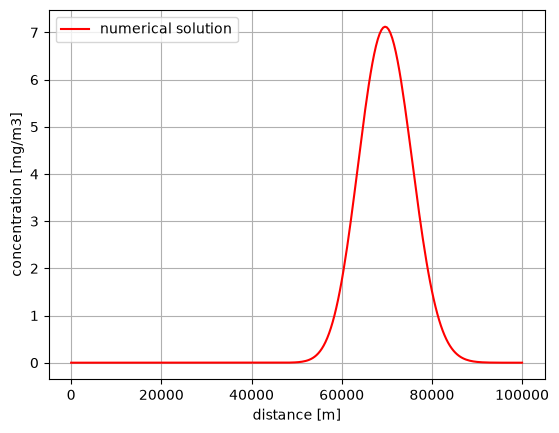

In [4]:
# number of timesteps
N = int(Tend/dt)   # 120 000 / 600 = 200 -> last row of c, i.e. t = Tend

plt.plot(x,c[N,:],'r',label='numerical solution')
plt.legend(loc='upper left')
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.grid()

Compare the numerical solution with your answers from **Task 1.1**.

>**Task 1.4**
>
>What are the Courant and mesh P&eacute;clet numbers?


**Answer Task 1.4**

With $u = 0.5$ m/s, $K = 100$ m$^2$/s, $\Delta x = 400$ m and $\Delta t = 600$ s:

**Courant number**

$$
\sigma = \frac{u\,\Delta t}{\Delta x} = \frac{0.5 \cdot 600}{400} = \mathbf{0.75}
$$

In one time step the cloud moves $u\Delta t = 300$ m, which is less than one grid cell, so $\sigma < 1$.

**Mesh Péclet number**

$$
P_\Delta = \frac{u\,\Delta x}{K} = \frac{0.5 \cdot 400}{100} = \mathbf{2}
$$

This is exactly at the limit $|P_\Delta| \le 2$ for central differences. Advection and diffusion are equally important at the scale of one grid cell, and the solution should be free of spurious oscillations (wiggles).

For reference, the diffusion number is $q = K\Delta t/\Delta x^2 = 100 \cdot 600 / 400^2 = 0.375$ (check: $\sigma/q = 0.75/0.375 = 2 = P_\Delta$).

This run uses Crank–Nicolson, which is unconditionally stable, so the time step is not limited by stability. It also uses central differences, and since $P_\Delta \le 2$ the numerical solution in Task 1.3 is smooth and wiggle-free.


## Part II: accuracy

### Time integration using the $\theta$-method

During the course you were introduced to the following two time integration methods, namely
- the forward Euler scheme and
- the backward Euler scheme.

Each of these methods has its advantages and disadvantages. Basically, the forward Euler is conditionally stable
while the backward Euler is unconditionally stable. On the other hand, the former is simple to implement and also
cheap in terms of function evaluations while the latter usually results into a system of equations that need
to be solved.
Both methods, however, are first order accurate in time, which could potentially be a disadvantage in many applications.
Now let us take a look at how we can improve this.

Consider the following first order ODE

$$
  \frac{dy}{dt} = f(y)
$$

where we seek for a solution $y(t)$ in the range $0 \leq t \leq T_{\text{end}}$.
This time frame is discretized into a number of steps with a step size of $\Delta t$:
$\{t_n = n\Delta t \,\,|\,\, n = 0, 1, 2, \cdots\}$.
Then, the **forward (explicit) Euler scheme** is given by

$$
  \frac{y^{n+1}-y^n}{\Delta t} = f(y^n)
$$

while the **backward (implicit) Euler scheme** reads

$$
  \frac{y^{n+1}-y^n}{\Delta t} = f(y^{n+1})
$$

Again, both schemes have a truncation error of $\tau_{\Delta t} = \mathcal{O}(\Delta t)$.

If we take the average of the forward and backward Euler schemes, we get

$$
  \frac{y^{n+1}-y^n}{\Delta t} = \frac 12 f(y^n) + \frac 12 f(y^{n+1})
$$

which is known as the **Crank-Nicolson scheme** or the **trapezoidal rule**.
Since the last term of the right-hand side needs to be evaluated based on the solution at the next time step $y^{n+1}$,
the Crank-Nicolson scheme is regarded as *implicit*. Like the backward Euler, this scheme has the disadvantage of the required
system of equations to be solved, but has the advantageous property of unconditional stability.

The reason behind averaging the forward and backward Euler schemes is to improve the accuracy of the resulting scheme.
Indeed, the truncation error of the Crank-Nicolson scheme is given as $\tau_{\Delta t} = \mathcal{O}(\Delta t^2)$.

All the three mentioned schemes above can be generalized to an arbitrary weighted average of $f(y^n)$ and $f(y^{n+1})$, as follows

$$
  \frac{y^{n+1}-y^n}{\Delta t} = \theta\, f(y^{n+1}) + \left ( 1 - \theta \right ) \,f(y^n) 
$$

with $0 \leq \theta \leq 1$ a weight parameter to be chosen. This scheme is called the $\theta$-method
and is explicit if $\theta = 0$ and implicit if $0 < \theta \leq 1$. The parameter $\theta$ is called the
**implicitness parameter** (last argument of the above script). In practice, we will be almost exclusively interested in either
- forward Euler ($\theta = 0$) or
- backward Euler ($\theta = 1$) or
- Crank-Nicolson ($\theta = 1/2$)

In the remainder of this assignment we will work with these three schemes.

>**Task 2.1**
>
>
>
>The goal of this assignment is to determine whether the explicit and implict Euler methods are indeed less accurate than the trapezoidal rule. To this end, first:
> - repeat the previous calculation using a time step of 10 minutes, followed by a calculation with a time step of 5 minutes. 
> 
> Keep central differences for the spatial discretization. Compare both plots and write down your conclusions based on this comparison.
>
>Next: 
> - Perform the calculation again using the last time step, but this time apply the explicit Euler method instead of the trapezoidal rule. 
> - Continue halving the time step until there is no longer any discernible difference between the results of the last two calculations.
> - Repeat the same procedure but for the implicit Euler method. Include your graph and the observed time.
>
>Compare your result with that of the trapezoidal rule and explicit Euler.
>
>Explain your findings based on the notion of *order of accuracy*.


trapezoidal: max c (10 min) = 7.122, max c (5 min) = 7.119, max |difference| = 0.0160 mg/m3

explicit Euler: dt =  300.000 s, max c = 8.202
explicit Euler: dt =  150.000 s, max c = 7.610, max |difference with previous dt| = 0.5967
explicit Euler: dt =   75.000 s, max c = 7.353, max |difference with previous dt| = 0.2591
explicit Euler: dt =   37.500 s, max c = 7.233, max |difference with previous dt| = 0.1209
explicit Euler: dt =   18.750 s, max c = 7.175, max |difference with previous dt| = 0.0585
explicit Euler: dt =    9.375 s, max c = 7.146, max |difference with previous dt| = 0.0288
explicit Euler: no discernible difference anymore at dt = 9.375 s (= 0.16 min)

implicit Euler: dt =  300.000 s, max c = 6.353
implicit Euler: dt =  150.000 s, max c = 6.705, max |difference with previous dt| = 0.3535
implicit Euler: dt =   75.000 s, max c = 6.903, max |difference with previous dt| = 0.1991
implicit Euler: dt =   37.500 s, max c = 7.008, max |difference with previous dt| = 0.1060
impli

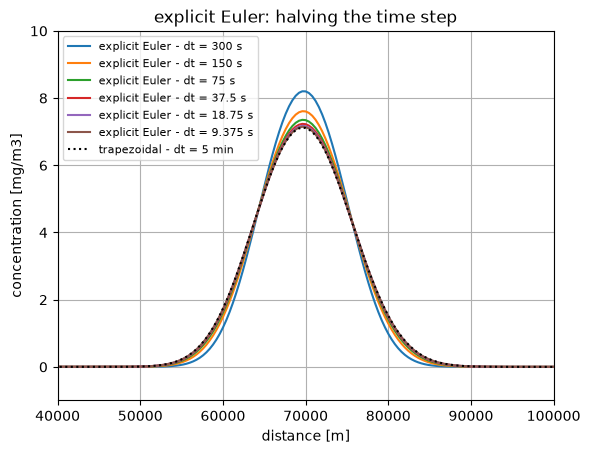

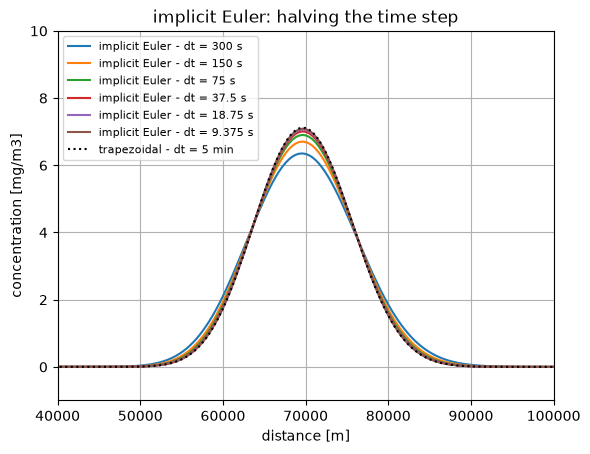

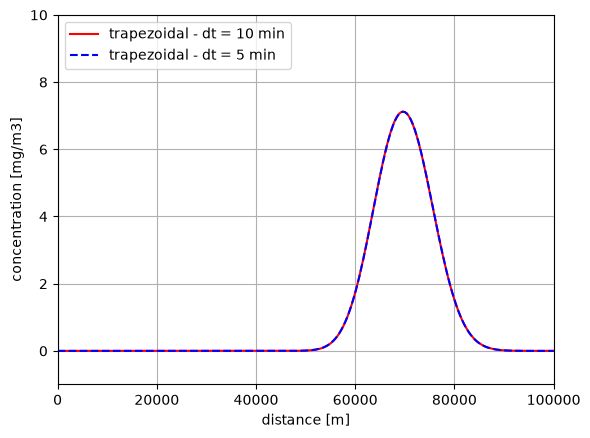

In [5]:
# Parameters for Task 2.1

# We do the first one for you!
dxmethod = 'central'
dtmethod = 'theta'

theta = 0.5

# replot the current result
plt.plot(x,c[N,:],'r',label='trapezoidal - dt = 10 min')

# reduce time step by factor 2
dt = dt / 2


# Now it's your turn! 

fig_cn = plt.gcf()          # keep a handle to this figure (trapezoidal rule)
c_cn10 = c[N,:].copy()      # trapezoidal solution with dt = 10 min

# --- (a) trapezoidal rule (Crank-Nicolson) with dt = 5 min ---
N = int(round(Tend/dt))
c = advdiff(u,K,c0,lenD,dt,Tend,dxmethod,dtmethod,theta)
c_cn5 = c[N,:].copy()
plt.plot(x,c_cn5,'b--',label='trapezoidal - dt = 5 min')
print(f'trapezoidal: max c (10 min) = {c_cn10.max():.3f}, max c (5 min) = {c_cn5.max():.3f}, '
      f'max |difference| = {np.max(np.abs(c_cn5 - c_cn10)):.4f} mg/m3\n')


def halve_until_converged(theta, dt_start, name, tol=0.05):
    """Run the theta-method, halving dt until two successive solutions at t = Tend
    differ by less than tol [mg/m3] (no discernible difference in the plot).
    Plots every run in a new figure and returns the last time step."""
    plt.figure()
    dt_k, c_prev = dt_start, None
    while True:
        N_k = int(round(Tend/dt_k))
        c_k = advdiff(u,K,c0,lenD,dt_k,Tend,dxmethod,dtmethod,theta)[N_k,:]
        plt.plot(x,c_k,label=f'{name} - dt = {dt_k:g} s')
        if c_prev is None:
            print(f'{name}: dt = {dt_k:8.3f} s, max c = {c_k.max():.3f}')
        else:
            diff = np.max(np.abs(c_k - c_prev))
            print(f'{name}: dt = {dt_k:8.3f} s, max c = {c_k.max():.3f}, '
                  f'max |difference with previous dt| = {diff:.4f}')
            if diff < tol:
                break
        c_prev = c_k
        dt_k = dt_k / 2
    plt.plot(x,c_cn5,'k:',label='trapezoidal - dt = 5 min')   # reference
    plt.axis(np.array([4e4,1e5,-1,10]))
    plt.title(f'{name}: halving the time step')
    plt.xlabel('distance [m]')
    plt.ylabel('concentration [mg/m3]')
    plt.legend(loc='upper left', fontsize=8)
    plt.grid()
    print(f'{name}: no discernible difference anymore at dt = {dt_k:g} s '
          f'(= {dt_k/60:.2f} min)\n')
    return dt_k

# --- (b) explicit (forward) Euler, theta = 0, start from dt = 5 min ---
dt_FE = halve_until_converged(0.0, dt, 'explicit Euler')

# --- (c) implicit (backward) Euler, theta = 1, start from dt = 5 min ---
dt_BE = halve_until_converged(1.0, dt, 'implicit Euler')

# go back to the first figure (trapezoidal rule, 10 min vs 5 min)
plt.figure(fig_cn.number)


# finalize the plot. Hint: plot them together on the same figure
plt.axis(np.array([0,lenD,-1,10]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper left")
plt.grid()


## Part III: effect of numerical diffusion

In this part of the assignment we will investigate the impact of numerical diffusion.
In general, there are two contributions to this numerical diffusion:
- the first order upwind scheme
- the $\theta$-method

To ensure that only numerical diffusion is at play, we set $K = 0$, so that there is no physical diffusion.
The other parameters of the previous runs in part I remain unchanged.

Since $K=0$, we solves the advection equation

$$
  \frac{\partial c}{\partial t} + v\,\frac{\partial c}{\partial x} = 0
$$

which represents the propagation of the substance in the river while the block shape remains unchanged throughout the journey.
In this way we can use this exact propagated solution for comparison with the obtained numerical solutions.

>**Task 3.1**
>
>Consider the same initial block-shaped profile of the cloud, with a maximum concentration of 10 mg/$m^{3}$ and a length of 10 km. Interpret the code below used to plot the cloud as it passes point B, 60 km downstream.
>


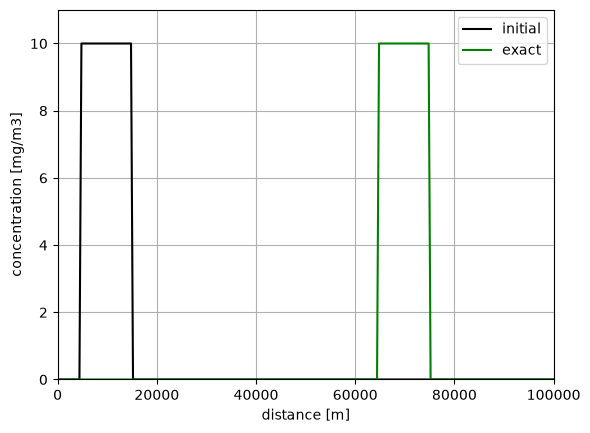

In [6]:
# true solution propagated

distance = 60000.
c1 = np.zeros(M)
c1[int(0.5 * lenC/dx + distance/dx):int(0.5 * lenC/dx + distance/dx) + int(lenC/dx) + 1] = 10.

plt.plot(x,c0,'k',label='initial')
plt.plot(x,c1,'g',label='exact')

# finalize the plot
plt.axis(np.array([0,100000,0,11]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper right")
plt.grid()

>**Task 3.2**
>
>Use function `advdiff` to do the following three runs:
>- first order upwind and $\theta = 0$ (FTBS)
>- central differences and $\theta = 0.5$ (central + trapezoidal)
>- first order upwind and $\theta = 1.0$ (BTBS)
>
>For these runs, set $\Delta x = 400$ m, $\Delta t = 600$ s and $K = 0$ $m^{2}$/s.
>
>Include a graph containing the results of the three runs together with the analytical solution of **Task 3.1**. Clearly mark which curve belongs to which run.
>
>Answer the following questions in your report.
>1. Which of the schemes has the most numerical diffusion? Estimate the amount of this numerical diffusion.
>2. Which scheme has no numerical diffusion and why?
>3. Which of the two contributions to numerical diffusion has the largest impact?
>   - the first order upwind scheme or
>   - the implicit Euler method
>4. Which of the schemes gives a non-negative solution? And do you think this has any connection to the answer to question 2? Explain your reasoning.
>


Courant number sigma = 0.75

FTBS (upwind + explicit Euler)  : max c =  9.663, min c =   0.000, estimated numerical diffusion =   23.1 m2/s
central + trapezoidal           : max c = 12.775, min c =  -2.575, estimated numerical diffusion =   none (peak not lowered)
BTBS (upwind + implicit Euler)  : max c =  5.786, min c =   0.000, estimated numerical diffusion =  161.2 m2/s


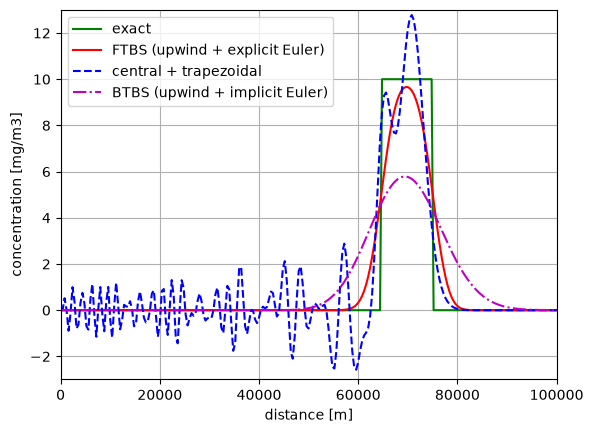

In [7]:
# parameters for Task 3.2
# we do the first one for you!

dtmethod = 'theta'
K = 0.

# plot true solution
plt.plot(x,c1,'g',label='exact')


# Now it's your turn!
from scipy.special import erfinv

# reset the baseline parameters (dt was halved in Task 2.1)
u = 0.5
dx = 400.
dt = 600.
Tend = distance / u          # 120 000 s: block centre travels 60 km
N = int(round(Tend/dt))      # 200 time steps

print(f'Courant number sigma = {u*dt/dx:.2f}\n')

runs = [('upwind',  0.0, 'r',   'FTBS (upwind + explicit Euler)'),
        ('central', 0.5, 'b--', 'central + trapezoidal'),
        ('upwind',  1.0, 'm-.', 'BTBS (upwind + implicit Euler)')]

for dxm, th, style, name in runs:
    c = advdiff(u,K,c0,lenD,dt,Tend,dxm,dtmethod,th)
    plt.plot(x,c[N,:],style,label=name)
    cmax, cmin = c[N,:].max(), c[N,:].min()
    # estimate of numerical diffusion: the K for which the exact diffusion solution
    # gives the same peak, c_max = c0 * erf(Lc / (4 sqrt(K t)))
    if cmax < 10.:
        K_num = (lenC / (4*np.sqrt(Tend)*erfinv(cmax/10.)))**2
        K_txt = f'{K_num:6.1f} m2/s'
    else:
        K_txt = '  none (peak not lowered)'
    print(f'{name:32s}: max c = {cmax:6.3f}, min c = {cmin:7.3f}, '
          f'estimated numerical diffusion = {K_txt}')

# plot the result
plt.axis(np.array([0,lenD,-3,13]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper left")
plt.grid()

**Answer Task 3.2**

Settings: $u = 0.5$ m/s, $K = 0$, $\Delta x = 400$ m, $\Delta t = 600$ s, so the Courant number is $\sigma = u\Delta t/\Delta x = 0.75$. Since $K = 0$, the exact solution is the block moved 60 km downstream with its shape unchanged (green curve). Any lowering or smearing of the block is therefore **numerical** diffusion.

The numerical diffusion of each scheme follows from the leading error terms:
- **Upwind in space** adds $\kappa_a = \dfrac{u\Delta x}{2} = \dfrac{0.5\cdot 400}{2} = 100$ m$^2$/s (book, advection-diffusion section).
- **Euler in time** adds $\pm\dfrac{u^2\Delta t}{2} = \dfrac{0.25 \cdot 600}{2} = 75$ m$^2$/s:
  - implicit Euler adds it ($+$, extra damping);
  - explicit Euler removes it ($-$, anti-diffusion).
- **Central differences and the trapezoidal rule** are both symmetric and second order. They add no numerical diffusion.

| Run | Numerical diffusion |
|---|---|
| FTBS ($\theta=0$, upwind) | $\dfrac{u\Delta x}{2} - \dfrac{u^2\Delta t}{2} = \dfrac{u\Delta x}{2}(1-\sigma) = 100 - 75 = 25$ m$^2$/s |
| Central + trapezoidal ($\theta = 0.5$) | $0$ |
| BTBS ($\theta=1$, upwind) | $\dfrac{u\Delta x}{2} + \dfrac{u^2\Delta t}{2} = \dfrac{u\Delta x}{2}(1+\sigma) = 100 + 75 = 175$ m$^2$/s |

**1. Most numerical diffusion.** **BTBS** has the most numerical diffusion, about **175 m$^2$/s**, because both of its contributions are diffusive and add up. Its block at B is strongly smeared into a low, wide bell. With the diffusion solution, $c_{\max} \approx 10\,\text{erf}\big(L_c/(4\sqrt{175\, t_B})\big) \approx 5.6$ mg/m$^3$. By comparison, FTBS has about 25 m$^2$/s and keeps a peak of about 9.6 mg/m$^3$. The cell above also prints, for each run, the diffusion coefficient that gives the same peak in the exact diffusion solution. This is an independent estimate from the simulation.

**2. No numerical diffusion.** **Central differences with the trapezoidal rule** have none.
- Central differences are symmetric. As the book shows, the semi-discrete system has a skew-symmetric matrix with purely imaginary eigenvalues, so it is undamped.
- The trapezoidal rule is symmetric in time (second order) and keeps this undamped behaviour.

The leading errors are therefore dispersive, not diffusive: the peak is not lowered, but the block's sharp edges produce oscillations.

**3. Largest contribution.** The **first order upwind scheme** contributes more: $u\Delta x/2 = 100$ m$^2$/s, against $u^2\Delta t/2 = 75$ m$^2$/s for implicit Euler. Their ratio is $\dfrac{u^2\Delta t/2}{u\Delta x/2} = \sigma = 0.75 < 1$. Implicit Euler would only dominate if $\sigma > 1$.

**4. Non-negative solutions.**
- **FTBS is non-negative.** For $u > 0$ it can be written as $c_m^{n+1} = (1-\sigma)c_m^n + \sigma c_{m-1}^n$. With $0 \le \sigma \le 1$ (here 0.75), this is a weighted average of non-negative values, so the result is non-negative (book, CFL condition).
- **BTBS is non-negative** for any $\Delta t$. Each new value is $c_m^{n+1} = \dfrac{c_m^n + \sigma c_{m-1}^{n+1}}{1+\sigma}$, again a positive combination of non-negative values.
- **Central + trapezoidal is not non-negative.** It produces wiggles with negative values (undershoots) and overshoots above 10 mg/m$^3$ around the sharp edges of the block. With $K = 0$ the mesh Péclet number is $P_\Delta = u\Delta x/K = \infty$, far above the limit $|P_\Delta| \le 2$ for central differences.

**Connection with question 2: yes.** The schemes that stay non-negative are exactly the ones with numerical diffusion. Upwinding adds just enough diffusion to damp the short-wave components that a sharp front creates (the book shows that upwind has no wiggles for any $P_\Delta$). The scheme without numerical diffusion has nothing to damp these components, so they appear as wiggles and negative concentrations.

This is a trade-off. Non-negativity is bought with first order accuracy and a smeared front, while second order accuracy without diffusion gives a sharp but oscillating front. It is a general property: a linear scheme that never creates new extrema can be at most first order accurate.


>**Task 3.3**
>
>Carry out two runs with the FTCS scheme:
>- without diffusion
>- with diffusion $K = 75$ $m^{2}$/s
>
>In both cases, set $u = 0.5$ m/s, $\Delta x = 400$ m and $\sigma = 0.75$.
>
>Make a graph showing the results without diffusion and with diffusion.
>Also make sure that the solution at *final time step* does not leave the domain. Clearly mark the curves.
>
>What is the mesh P&eacute;clet number?
>
>Explain your findings.


without diffusion: min c = -1.254e+19, max c = 1.255e+19
with diffusion   : min c = -1.950, max c = 11.953
sigma = 0.750, q = K dt/dx^2 = 0.2812, sigma^2 = 0.5625, 2q = 0.5625
mesh Peclet number =  2.6666666666666665


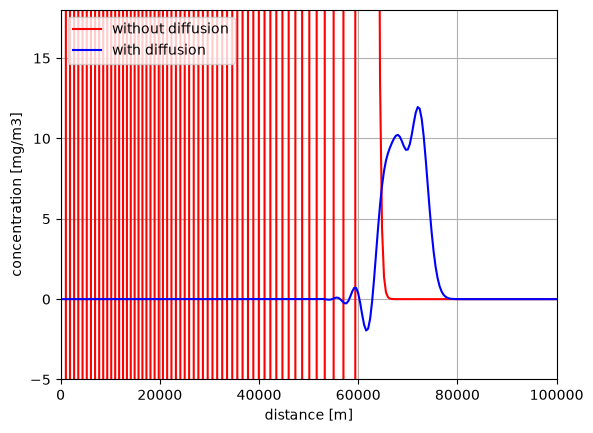

In [9]:

# parameters for Task 3.3

u = 0.5
K = 75.
dx = 400.
sigma = 0.75
distance=60000.

# compute the end time and time step
Tend = np.ceil(distance/u)
dt = np.floor(sigma * dx / u)
N = int(Tend/dt)

# solve the advection-diffusion equation using the FTCS scheme
# (FTCS = forward Euler in time (theta = 0) + central differences in space)
# without diffusion

c = advdiff(u,0.,c0,lenD,dt,Tend,'central','theta',0.)
plt.plot(x,c[N,:],'r',label='without diffusion')
print(f'without diffusion: min c = {c[N,:].min():.3e}, max c = {c[N,:].max():.3e}')

# with diffusion

c = advdiff(u,K,c0,lenD,dt,Tend,'central','theta',0.)
plt.plot(x,c[N,:],'b',label='with diffusion')
print(f'with diffusion   : min c = {c[N,:].min():.3f}, max c = {c[N,:].max():.3f}')
print(f'sigma = {u*dt/dx:.3f}, q = K dt/dx^2 = {K*dt/dx**2:.4f}, sigma^2 = {(u*dt/dx)**2:.4f}, 2q = {2*K*dt/dx**2:.4f}')
print('mesh Peclet number = ',u*dx/K)

# finalize the plot
plt.axis(np.array([0,lenD,-5,18]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper left")
plt.grid()

**Answer Task 3.3**

Settings: $u = 0.5$ m/s, $\Delta x = 400$ m, $\sigma = 0.75$, so $\Delta t = 600$ s, $T_{\text{end}} = 120\,000$ s and $N = 200$. At $T_{\text{end}}$ the cloud is centred at about 70 km and ends well before $x = 100$ km, so the solution stays inside the domain.

**Mesh Péclet number** (with diffusion):

$$
P_\Delta = \frac{u\Delta x}{K} = \frac{0.5\cdot 400}{75} \approx \mathbf{2.67}
$$

Without diffusion, $P_\Delta = \infty$.

For reference, the diffusion number is $q = K\Delta t/\Delta x^2 = 75\cdot 600/400^2 = 0.281$, and $\sigma/q = P_\Delta$.

**Without diffusion: unstable.** The computed solution reaches values of about $\pm 1.3\cdot 10^{19}$ mg/m$^3$, completely outside the plot. This is expected: FTCS for the pure advection equation is unstable for *any* time step (book, advection equation). Central differences give purely imaginary eigenvalues, and forward Euler amplifies every such mode in each step. The worst mode grows by a factor $\sqrt{1+\sigma^2} = 1.25$ per step, and $1.25^{200} \approx 10^{19}$, which matches the computed magnitude.

**With diffusion ($K = 75$ m$^2$/s): stable, but with wiggles.** The solution stays bounded, but it is clearly wrong. The maximum is $\approx 12.0$ mg/m$^3$, which overshoots the initial 10 mg/m$^3$, impossible for diffusion. The minimum is $\approx -2.0$ mg/m$^3$, a negative concentration.

- **Why it is stable.** As found in Task 3.2, explicit Euler adds an *anti*-diffusion of $-u^2\Delta t/2 = -0.25\cdot 600/2 = -75$ m$^2$/s. The physical diffusion $K = 75$ m$^2$/s exactly cancels it. Equivalently, $\sigma^2 = 2q$ ($0.5625 = 0.5625$), which is exactly the stability limit of FTCS for advection-diffusion. Any smaller $K$ would make the scheme unstable again.
- **Why it wiggles.** Because the two diffusions cancel, the net leading-order diffusion is zero. The scheme then behaves like a scheme *without* numerical diffusion: the error is dispersive, and the sharp edges of the block produce oscillations. This is the same behaviour as central + trapezoidal in Task 3.2 (max 12.8, min $-2.6$ mg/m$^3$).
- **Book criterion.** Positivity requires $q \le \tfrac12$ (satisfied: $0.281$) **and** $|P_\Delta| \le 2$ (violated: $2.67$). In the FTCS update
$$
c_m^{n+1} = \left(q - \tfrac12\sigma\right)c_{m+1}^n + (1-2q)\,c_m^n + \left(q + \tfrac12\sigma\right)c_{m-1}^n,
$$
the coefficient of $c_{m+1}^n$ is negative: $q - \tfrac12\sigma = 0.281 - 0.375 = -0.094$. So the scheme can create negative values and new extrema.

**Conclusion.** FTCS can only be used for advection-dominated transport because of physical diffusion, and that diffusion must satisfy two conditions:
- It must at least compensate the anti-diffusion of forward Euler, $K \ge u^2\Delta t/2$ (stability).
- The grid must resolve the balance between advection and diffusion, $P_\Delta \le 2$, i.e. $\Delta x \le 2K/u = 300$ m (no wiggles).

With $K = 75$ m$^2$/s and $\Delta x = 400$ m the first condition is only just met and the second is violated. The result is stable but shows overshoots and negative concentrations.


## Part IV: numerical stability

In this part of the assignment we will explore the stability of the various schemes.

>**Task 4.1**
>
>We study the stability (and accuracy) of the following three schemes:
>- the FTCS scheme,
>- the FTBS scheme, and
>- Crank-Nicolson with central differences.
>
>Do the following:
>
>1. Try to find the maximum time step for each scheme such that the solution is about to be stable.
>2. Plot the stable solution of the given scheme in a graph and write down the time step you found. You will need these results later for the stability analysis.
>
>Use the parameters from the last run in the previous question, except $K = 125$ $m^{2}$/s.
>
>
>1. Which of the schemes is/are unconditionally stable? 
>2. Which of the schemes is the most accurate one? Why?
>3. Which of the numerical solutions has the largest maximum? Why?
>


maximum time step =  640.0
maximum time step FTBS =  355.0
FTCS with dt = 704 s (10% above limit): max |c| = 7.185e+12
FTBS with dt = 391 s (10% above limit): max |c| = 9.227e+22

sigma, q, P for FTCS: 0.800, 0.500, 1.60
sigma, q for FTBS   : 0.444, 0.277

maximum concentration at final time:
  exact           : max c = 6.573, min c = 0.000, max |c - exact| = 0.000
  FTCS            : max c = 8.873, min c = 0.000, max |c - exact| = 2.327
  FTBS            : max c = 5.701, min c = 0.000, max |c - exact| = 0.880
  CN dt=640 s     : max c = 6.588, min c = 0.000, max |c - exact| = 0.173
  CN dt=6000 s    : max c = 6.538, min c = -0.711, max |c - exact| = 1.667


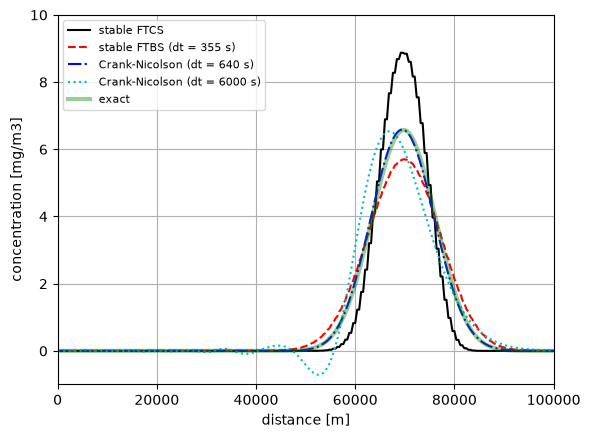

In [10]:
# time step based on stability of FTCS
K = 125.
dt2 = np.floor(0.5 * dx*dx / K)

print('maximum time step = ',dt2)
ce = advdiff(u,K,c0,lenD,dt2,Tend,'central','theta',0.)
N2 = int(Tend/dt2)
plt.plot(x,ce[N2,:],'k',label='stable FTCS')

# time step based on stability of FTBS
# FTBS: c_m^{n+1} = q c_{m+1} + (1 - 2q - sigma) c_m + (q + sigma) c_{m-1}
# all coefficients >= 0 (stable, non-negative) if 1 - 2q - sigma >= 0
#   ->  dt <= 1 / (2K/dx^2 + u/dx)
dt3 = np.floor(1. / (2.*K/dx**2 + u/dx))
print('maximum time step FTBS = ',dt3)
cu = advdiff(u,K,c0,lenD,dt3,Tend,'upwind','theta',0.)
N3 = int(Tend/dt3)
plt.plot(x,cu[N3,:],'r--',label=f'stable FTBS (dt = {dt3:g} s)')

# time step based on stability of trapezoidal rule/central differences
# Crank-Nicolson is unconditionally stable: there is no maximum time step.
# (a) same time step as FTCS, for a fair comparison of accuracy
dt4 = dt2
cc = advdiff(u,K,c0,lenD,dt4,Tend,'central','theta',0.5)
N4 = int(Tend/dt4)
plt.plot(x,cc[N4,:],'b-.',label=f'Crank-Nicolson (dt = {dt4:g} s)')
# (b) a very large time step (sigma = 7.5) is still stable
dt5 = 6000.
cc5 = advdiff(u,K,c0,lenD,dt5,Tend,'central','theta',0.5)
N5 = int(Tend/dt5)
plt.plot(x,cc5[N5,:],'c:',label=f'Crank-Nicolson (dt = {dt5:g} s)')

# reference: exact solution (block of the grid: 26 points = 10.4 km, centred at 9.8 km)
from scipy.special import erf
Lg = np.count_nonzero(c0) * dx
xc = x[c0 > 0].mean()
s = 2*np.sqrt(K*Tend)
cex = 5.*(erf((0.5*Lg - (x - xc - u*Tend))/s) + erf((0.5*Lg + (x - xc - u*Tend))/s))
plt.plot(x,cex,'g',lw=3,alpha=0.4,label='exact')

# check the limits: 10% above the maximum time step the explicit schemes blow up
for name, dxm, dtl in [('FTCS','central',dt2), ('FTBS','upwind',dt3)]:
    dtu = 1.1*dtl
    cx = advdiff(u,K,c0,lenD,dtu,Tend,dxm,'theta',0.)
    print(f'{name} with dt = {dtu:.0f} s (10% above limit): max |c| = {np.abs(cx[int(Tend/dtu),:]).max():.3e}')

print(f'\nsigma, q, P for FTCS: {u*dt2/dx:.3f}, {K*dt2/dx**2:.3f}, {u*dx/K:.2f}')
print(f'sigma, q for FTBS   : {u*dt3/dx:.3f}, {K*dt3/dx**2:.3f}')
print('\nmaximum concentration at final time:')
for name, cn in [('exact',cex), ('FTCS',ce[N2,:]), ('FTBS',cu[N3,:]),
                 (f'CN dt={dt4:g} s',cc[N4,:]), (f'CN dt={dt5:g} s',cc5[N5,:])]:
    print(f'  {name:16s}: max c = {cn.max():.3f}, min c = {cn.min():.3f}, '
          f'max |c - exact| = {np.abs(cn - cex).max():.3f}')

# finalize the plot
plt.axis(np.array([0,lenD,-1,10]))
plt.xlabel('distance [m]')
plt.ylabel('concentration [mg/m3]')
plt.legend(loc = "upper left", fontsize=8)
plt.grid()

> By Marcel Zijlema, Delft University of Technology. CC BY 4.0, more info [on the Credits page of Workbook](https://mude.citg.tudelft.nl/workbook-2026/credits.html).